In [ ]:
# Bank Customer Churn Prediction and Cost-Sensitive Retention System Using Customer Lifetime Value

## Project Objective

This project develops a machine learning-based system to predict bank customer churn and prioritize retention efforts by combining churn probability, estimated customer lifetime value (LTV), and retention intervention cost.

## Machine Learning Models

- Logistic Regression — Baseline
- Random Forest
- XGBoost
- LightGBM

## Final System

The best-performing model will be selected after model comparison, cross-validation, and hyperparameter tuning. The selected model will generate customer-level churn probabilities, which will then be integrated with the LTV and cost-sensitive retention modules.

## Deployment

The final trained model will be integrated into a Streamlit application where users can enter customer information and receive churn probability, estimated LTV, retention priority, and recommended retention action.

In [453]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [454]:
df = pd.read_csv(r"C:\Users\hrish\Downloads\arc\Churn_Modelling.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [455]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [456]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 14


In [457]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [458]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [459]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [460]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [461]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [462]:
print(df["Exited"].value_counts())


Exited
0    7963
1    2037
Name: count, dtype: int64


In [463]:
print(df["Exited"].value_counts(normalize=True) * 100)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


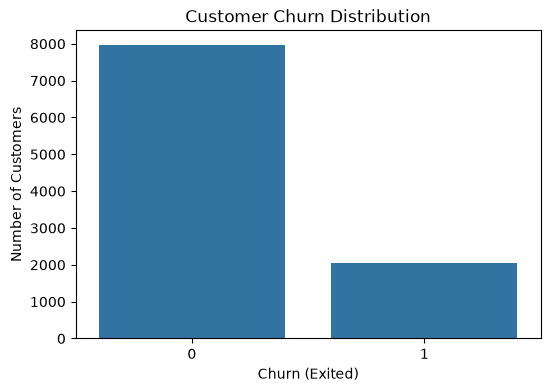

In [464]:
plt.figure(figsize=(6, 4))

sns.countplot(x="Exited", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (Exited)")
plt.ylabel("Number of Customers")
plt.show()

In [465]:
df_clean = df.copy()

print("Copy created successfully.")

Copy created successfully.


In [466]:
df_clean = df_clean.drop(columns=["RowNumber", "CustomerId", "Surname"])

print("Unnecessary columns removed.")
print(df_clean.head())

Unnecessary columns removed.
   CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
0          619    France  Female   42       2       0.00              1   
1          608     Spain  Female   41       1   83807.86              1   
2          502    France  Female   42       8  159660.80              3   
3          699    France  Female   39       1       0.00              2   
4          850     Spain  Female   43       2  125510.82              1   

   HasCrCard  IsActiveMember  EstimatedSalary  Exited  
0          1               1        101348.88       1  
1          0               1        112542.58       0  
2          1               0        113931.57       1  
3          0               0         93826.63       0  
4          1               1         79084.10       0  


In [467]:
print(df_clean.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [468]:
df_clean.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [469]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [470]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [471]:
df_clean.dtypes

CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [472]:
print("Geography:", df_clean["Geography"].unique())
print("Gender:", df_clean["Gender"].unique())

Geography: <ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
Gender: <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str


In [473]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
HasCrCard,10000.0,0.705500,0.455840,0.00,0.00,1.000,1.0000,1.00
IsActiveMember,10000.0,0.515100,0.499797,0.00,0.00,1.000,1.0000,1.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48
Exited,10000.0,0.203700,0.402769,0.00,0.00,0.000,0.0000,1.00


In [474]:
print("Credit Score range:")
print(df_clean["CreditScore"].min(), "-", df_clean["CreditScore"].max())

print("\nAge range:")
print(df_clean["Age"].min(), "-", df_clean["Age"].max())

print("\nTenure range:")
print(df_clean["Tenure"].min(), "-", df_clean["Tenure"].max())

print("\nNumber of products:")
print(df_clean["NumOfProducts"].unique())

Credit Score range:
350 - 850

Age range:
18 - 92

Tenure range:
0 - 10

Number of products:
[1 3 2 4]


In [475]:
print(df_clean["Exited"].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64


In [476]:
print(df_clean["Exited"].value_counts(normalize=True) * 100)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


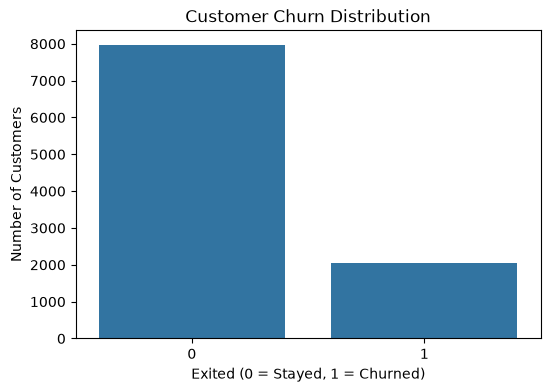

In [477]:
plt.figure(figsize=(6, 4))

sns.countplot(x="Exited", data=df_clean)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

In [478]:
churn_percentage = df_clean["Exited"].value_counts(normalize=True) * 100

print("Churn Distribution:")
print(churn_percentage)
print(f"Stayed: {churn_percentage[0]:.2f}%")
print(f"Churned: {churn_percentage[1]:.2f}%")

Churn Distribution:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64
Stayed: 79.63%
Churned: 20.37%


In [479]:
geo_churn = pd.crosstab(
    df_clean["Geography"],
    df_clean["Exited"],
    normalize="index"
) * 100

print(geo_churn)

Exited             0          1
Geography                      
France     83.845233  16.154767
Germany    67.556796  32.443204
Spain      83.326605  16.673395


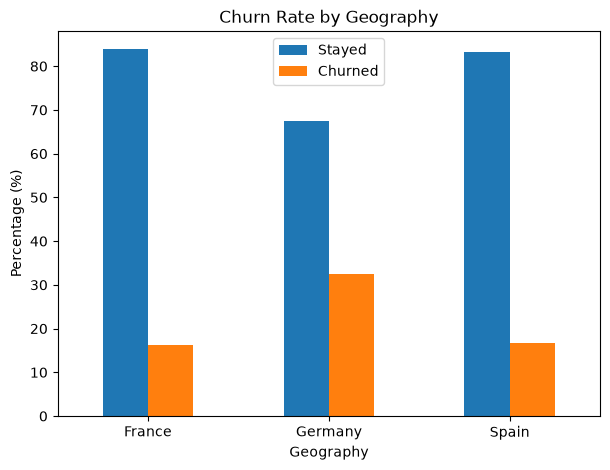

In [480]:
geo_churn.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

In [481]:
gender_churn = pd.crosstab(
    df_clean["Gender"],
    df_clean["Exited"],
    normalize="index"
) * 100

print(gender_churn)

Exited          0          1
Gender                      
Female  74.928461  25.071539
Male    83.544072  16.455928


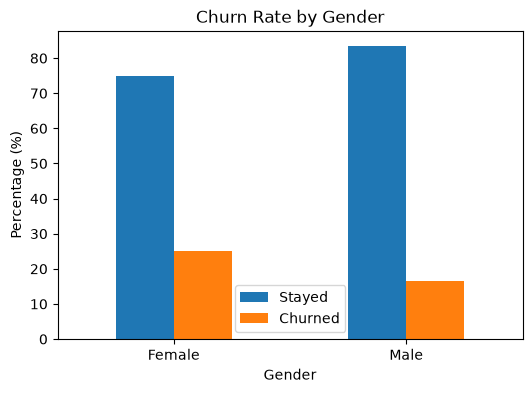

In [482]:
gender_churn.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

In [483]:
active_churn = pd.crosstab(
    df_clean["IsActiveMember"],
    df_clean["Exited"],
    normalize="index"
) * 100

print(active_churn)

Exited                  0          1
IsActiveMember                      
0               73.149103  26.850897
1               85.730926  14.269074


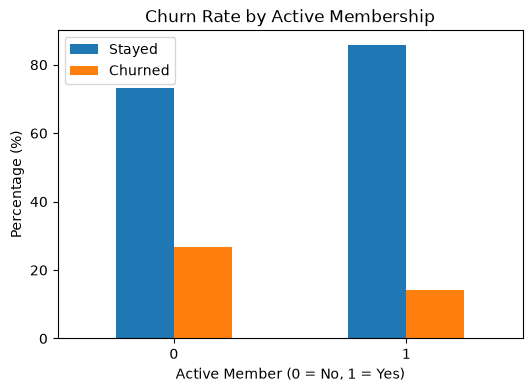

In [484]:
active_churn.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Churn Rate by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

In [485]:
product_churn = pd.crosstab(
    df_clean["NumOfProducts"],
    df_clean["Exited"],
    normalize="index"
) * 100

print(product_churn)

Exited                 0           1
NumOfProducts                       
1              72.285602   27.714398
2              92.418301    7.581699
3              17.293233   82.706767
4               0.000000  100.000000


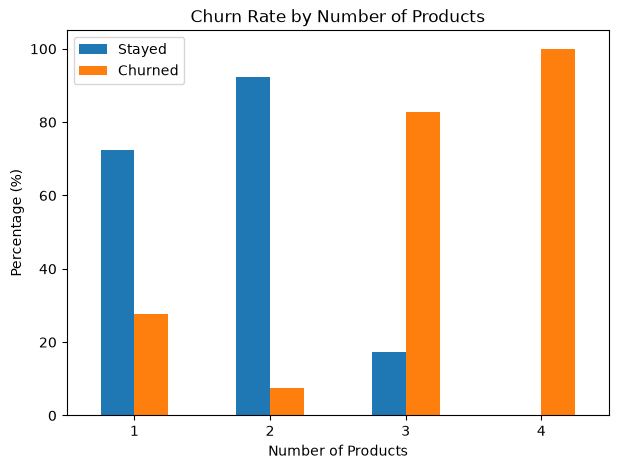

In [486]:
product_churn.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

In [487]:
df_eda = df_clean.copy()

df_eda["TenureGroup"] = pd.cut(
    df_eda["Tenure"],
    bins=[-1, 2, 5, 8, 10],
    labels=["0-2", "3-5", "6-8", "9-10"]
)
tenure_churn = pd.crosstab(
    df_eda["TenureGroup"],
    df_eda["Exited"],
    normalize="index"
) * 100

print(tenure_churn)

Exited               0          1
TenureGroup                      
0-2          78.846154  21.153846
3-5          79.235880  20.764120
6-8          81.125828  18.874172
9-10         78.697422  21.302578


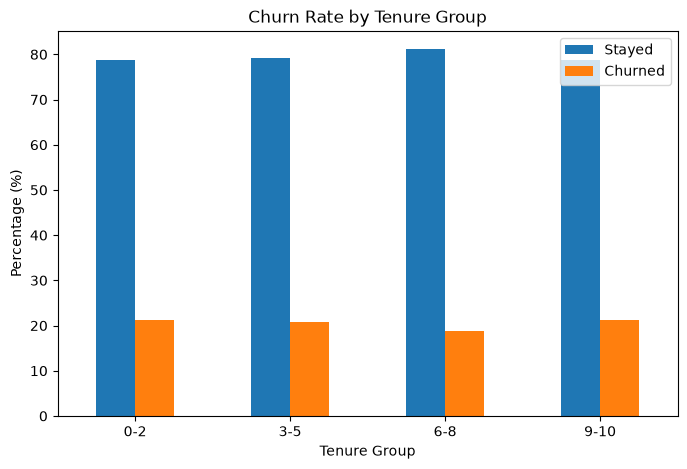

In [488]:
tenure_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])

plt.show()

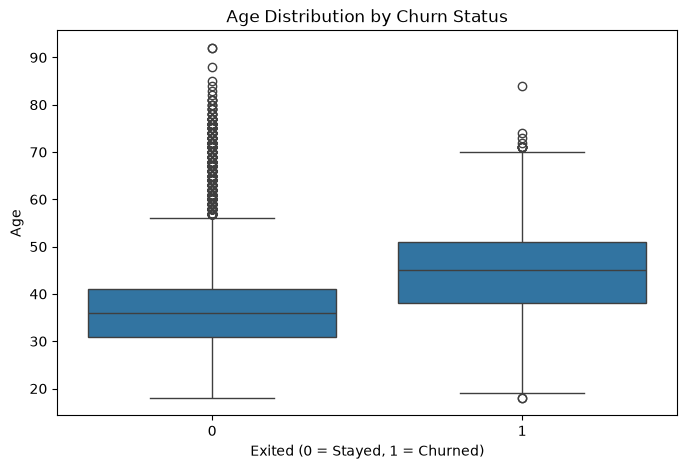

In [489]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Exited",
    y="Age",
    data=df_clean
)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Age")

plt.show()

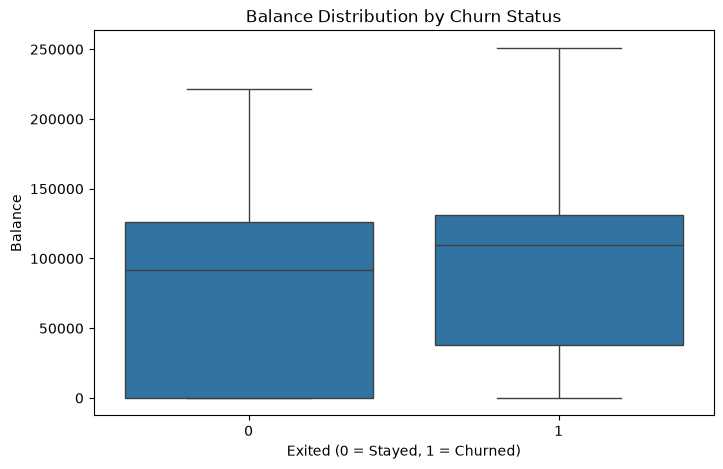

In [490]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Exited",
    y="Balance",
    data=df_clean
)

plt.title("Balance Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Balance")

plt.show()

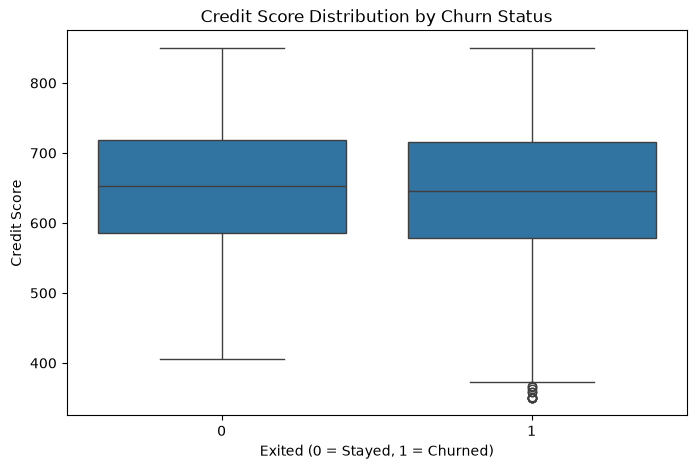

In [491]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Exited",
    y="CreditScore",
    data=df_clean
)

plt.title("Credit Score Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Credit Score")

plt.show()

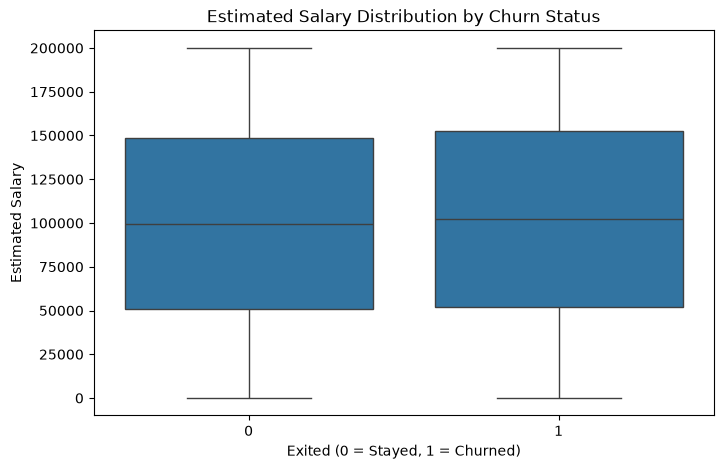

In [492]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Exited",
    y="EstimatedSalary",
    data=df_clean
)

plt.title("Estimated Salary Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Estimated Salary")

plt.show()

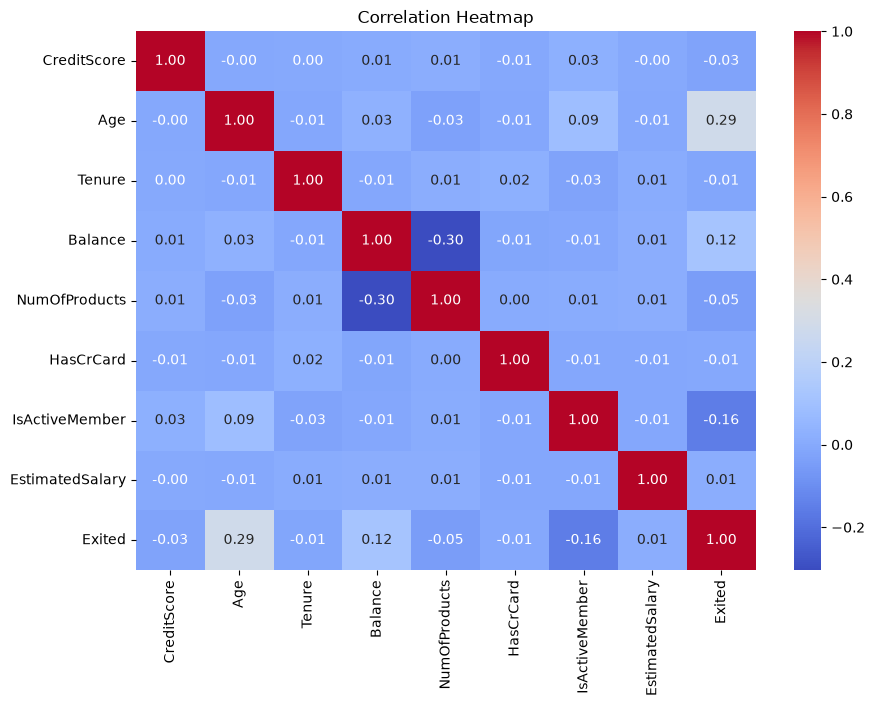

In [493]:
numeric_cols = df_clean.select_dtypes(include=np.number)

correlation = numeric_cols.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [494]:
print("EDA Summary")
print("=" * 50)

print("\nAverage values by churn status:")
print(
    df_clean.groupby("Exited")[
        ["CreditScore", "Age", "Tenure", "Balance",
         "NumOfProducts", "EstimatedSalary"]
    ].mean()
)

EDA Summary

Average values by churn status:
        CreditScore        Age    Tenure       Balance  NumOfProducts  \
Exited                                                                  
0        651.853196  37.408389  5.033279  72745.296779       1.544267   
1        645.351497  44.837997  4.932744  91108.539337       1.475209   

        EstimatedSalary  
Exited                   
0          99738.391772  
1         101465.677531  


In [495]:
df_model = df_clean.copy()

print("Model dataset created.")
print(df_model.shape)

Model dataset created.
(10000, 11)


In [496]:
df_model["BalanceSalaryRatio"] = (
    df_model["Balance"] / (df_model["EstimatedSalary"] + 1)
)
df_model[["Balance", "EstimatedSalary", "BalanceSalaryRatio"]].head()

,Balance,EstimatedSalary,BalanceSalaryRatio
0,0.00,101348.88,0.000000
1,83807.86,112542.58,0.744670
2,159660.80,113931.57,1.401362
3,0.00,93826.63,0.000000
4,125510.82,79084.10,1.587035


In [497]:
df_model["ProductEngagementScore"] = (
    df_model["NumOfProducts"] * (1 + df_model["IsActiveMember"])
)
df_model[
    ["NumOfProducts", "IsActiveMember", "ProductEngagementScore"]
].head()

,NumOfProducts,IsActiveMember,ProductEngagementScore
0,1,1,2
1,1,1,2
2,3,0,3
3,2,0,2
4,1,1,2


In [498]:
df_model["TenureBucket"] = pd.cut(
    df_model["Tenure"],
    bins=[-1, 2, 5, 8, 10],
    labels=["0-2", "3-5", "6-8", "9-10"]
)
df_model[["Tenure", "TenureBucket"]].head(10)

,Tenure,TenureBucket
0,2,0-2
1,1,0-2
2,8,6-8
3,1,0-2
4,2,0-2
5,8,6-8
6,7,6-8
7,4,3-5
8,4,3-5
9,2,0-2


In [499]:
print(df_model["TenureBucket"].value_counts().sort_index())

TenureBucket
0-2     2496
3-5     3010
6-8     3020
9-10    1474
Name: count, dtype: int64


In [500]:
df_model["InactiveFlag"] = (
    df_model["IsActiveMember"] == 0
).astype(int)
df_model[
    ["IsActiveMember", "InactiveFlag"]
].head(10)

,IsActiveMember,InactiveFlag
0,1,0
1,1,0
2,0,1
3,0,1
4,1,0
5,0,1
6,1,0
7,0,1
8,1,0
9,1,0


In [501]:
df_model["AgeGroup"] = pd.cut(
    df_model["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)
print(df_model["AgeGroup"].value_counts().sort_index())

AgeGroup
18-25     611
26-35    3542
36-45    3736
46-55    1311
56+       800
Name: count, dtype: int64


In [502]:
print("Columns after feature engineering:")
print(df_model.columns.tolist())

Columns after feature engineering:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'BalanceSalaryRatio', 'ProductEngagementScore', 'TenureBucket', 'InactiveFlag', 'AgeGroup']


In [503]:
df_model[
    [
        "BalanceSalaryRatio",
        "ProductEngagementScore",
        "InactiveFlag"
    ]
].describe()

,BalanceSalaryRatio,ProductEngagementScore,InactiveFlag
count,10000.000000,10000.000000,10000.000000
mean,3.790150,2.321200,0.484900
std,100.055758,1.200156,0.499797
min,0.000000,1.000000,0.000000
25%,0.000000,1.000000,0.000000
50%,0.746998,2.000000,0.000000
75%,1.514002,4.000000,1.000000
max,9770.883148,8.000000,1.000000


In [504]:
print(
    "Total missing values after feature engineering:",
    df_model.isnull().sum().sum()
)

Total missing values after feature engineering: 0


In [505]:
df_model.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio,ProductEngagementScore,TenureBucket,InactiveFlag,AgeGroup
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,2,0-2,0,36-45
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744670,2,0-2,0,36-45
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.401362,3,6-8,1,36-45
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.000000,2,0-2,1,36-45
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587035,2,0-2,0,36-45


In [506]:
print("Final dataset shape:", df_model.shape)

Final dataset shape: (10000, 16)


In [507]:
X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 15)
y shape: (10000,)


In [508]:
print("Target variable:")
print(y.head())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(y.value_counts(normalize=True) * 100)

Target variable:
0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

Target distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Target percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [509]:
print("Features used for modelling:")
for i, col in enumerate(X.columns, start=1):
    print(i, "-", col)

Features used for modelling:
1 - CreditScore
2 - Geography
3 - Gender
4 - Age
5 - Tenure
6 - Balance
7 - NumOfProducts
8 - HasCrCard
9 - IsActiveMember
10 - EstimatedSalary
11 - BalanceSalaryRatio
12 - ProductEngagementScore
13 - TenureBucket
14 - InactiveFlag
15 - AgeGroup


In [510]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.200,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (8000, 15)
Testing set: (2000, 15)


In [511]:
stratify=y

In [512]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64

Testing target distribution:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [513]:
# Identify numerical and categorical features

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductEngagementScore', 'InactiveFlag']

Categorical features:
['Geography', 'Gender', 'TenureBucket', 'AgeGroup']


In [514]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [515]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [516]:
preprocessor.fit(X_train)

print("Preprocessor fitted successfully on training data.")

Preprocessor fitted successfully on training data.


In [517]:
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 25)
Processed testing shape: (2000, 25)


In [518]:
import numpy as np

print(
    "Missing values in processed training data:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in processed testing data:",
    np.isnan(X_test_processed).sum()
)

Missing values in processed training data: 0
Missing values in processed testing data: 0


In [519]:
print("First 5 rows of processed training data:")
print(X_train_processed[:5])

First 5 rows of processed training data:
[[ 1.058568    1.71508648  0.68472287 -1.22605881 -0.91025649  0.64104192
  -1.030206    1.04208392 -0.03684268 -1.09987483  1.030206    1.
   0.          0.          0.          1.          0.          0.
   1.          0.          0.          0.          0.          0.
   1.        ]
 [ 0.91362605 -0.65993547 -0.6962018   0.41328769 -0.91025649  0.64104192
  -1.030206   -0.62355635 -0.02254008 -1.09987483  1.030206    0.
   1.          0.          0.          1.          0.          1.
   0.          0.          0.          1.          0.          0.
   0.        ]
 [ 1.07927399 -0.18493108 -1.73189531  0.60168748  0.80883036  0.64104192
   0.97067965  0.30812779 -0.02815182  1.40007744 -0.97067965  0.
   1.          0.          1.          0.          1.          0.
   0.          0.          0.          0.          1.          0.
   0.        ]
 [-0.92920731 -0.18493108 -0.00573947 -1.22605881  0.80883036  0.64104192
  -1.030206   -0.2901991

In [520]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

print("\nProcessed feature names:")
for i, feature in enumerate(feature_names, start=1):
    print(i, "-", feature)

Number of processed features: 25

Processed feature names:
1 - num__CreditScore
2 - num__Age
3 - num__Tenure
4 - num__Balance
5 - num__NumOfProducts
6 - num__HasCrCard
7 - num__IsActiveMember
8 - num__EstimatedSalary
9 - num__BalanceSalaryRatio
10 - num__ProductEngagementScore
11 - num__InactiveFlag
12 - cat__Geography_France
13 - cat__Geography_Germany
14 - cat__Geography_Spain
15 - cat__Gender_Female
16 - cat__Gender_Male
17 - cat__TenureBucket_0-2
18 - cat__TenureBucket_3-5
19 - cat__TenureBucket_6-8
20 - cat__TenureBucket_9-10
21 - cat__AgeGroup_18-25
22 - cat__AgeGroup_26-35
23 - cat__AgeGroup_36-45
24 - cat__AgeGroup_46-55
25 - cat__AgeGroup_56+


In [521]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nPercentage:")
print(y_train.value_counts(normalize=True) * 100)

Before SMOTE:
Exited
0    6370
1    1630
Name: count, dtype: int64

Percentage:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64


In [522]:
!pip install imbalanced-learn

In [523]:
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully.")

SMOTE imported successfully.


In [524]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("SMOTE applied successfully.")

SMOTE applied successfully.


In [525]:
print("After SMOTE:")
print(y_train_smote.value_counts())

print("\nPercentage:")
print(y_train_smote.value_counts(normalize=True) * 100)

After SMOTE:
Exited
1    6370
0    6370
Name: count, dtype: int64

Percentage:
Exited
1    50.0
0    50.0
Name: proportion, dtype: float64


In [526]:
before = y_train.value_counts()
after = y_train_smote.value_counts()

print("Class distribution comparison")
print("--------------------------------")

print("\nBefore SMOTE:")
print(before)

print("\nAfter SMOTE:")
print(after)


Class distribution comparison
--------------------------------

Before SMOTE:
Exited
0    6370
1    1630
Name: count, dtype: int64

After SMOTE:
Exited
1    6370
0    6370
Name: count, dtype: int64


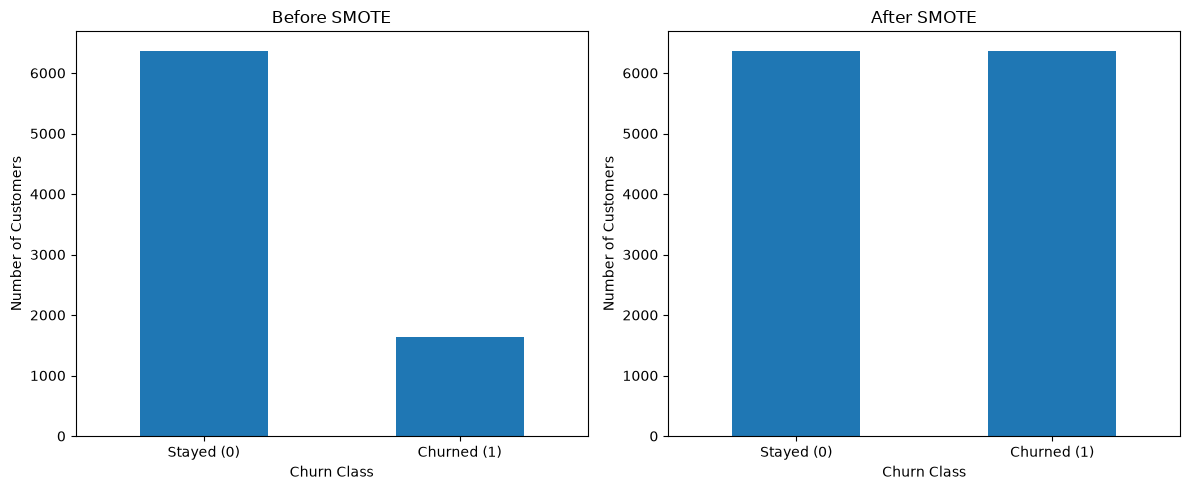

In [527]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
y_train.value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Churn Class")
axes[0].set_ylabel("Number of Customers")
axes[0].set_xticklabels(["Stayed (0)", "Churned (1)"], rotation=0)

# After SMOTE
y_train_smote.value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Churn Class")
axes[1].set_ylabel("Number of Customers")
axes[1].set_xticklabels(["Stayed (0)", "Churned (1)"], rotation=0)

plt.tight_layout()
plt.show()

In [528]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully.")

Logistic Regression imported successfully.


In [529]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created.")

Logistic Regression model created.


In [530]:
logistic_model.fit(
    X_train_smote,
    y_train_smote
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [531]:
y_pred_logistic = logistic_model.predict(
    X_test_processed
)

print("Predictions generated.")

Predictions generated.


In [532]:
y_prob_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("First 10 churn probabilities:")
print(y_prob_logistic[:10])

First 10 churn probabilities:
[0.32696433 0.46081827 0.34987387 0.2268807  0.21120874 0.25709212
 0.25546348 0.67561162 0.83170778 0.4693602 ]


In [533]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported.")

Evaluation metrics imported.


In [534]:
logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

logistic_precision = precision_score(
    y_test,
    y_pred_logistic
)

logistic_recall = recall_score(
    y_test,
    y_pred_logistic
)

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic
)

logistic_roc_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

logistic_pr_auc = average_precision_score(
    y_test,
    y_prob_logistic
)

print("Logistic Regression Baseline")
print("----------------------------")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_roc_auc, 4))
print("PR-AUC   :", round(logistic_pr_auc, 4))

Logistic Regression Baseline
----------------------------
Accuracy : 0.7315
Precision: 0.4055
Recall   : 0.6855
F1 Score : 0.5096
ROC-AUC  : 0.7845
PR-AUC   : 0.511


In [535]:
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=["Stayed", "Churned"]
    )
)

              precision    recall  f1-score   support

      Stayed       0.90      0.74      0.82      1593
     Churned       0.41      0.69      0.51       407

    accuracy                           0.73      2000
   macro avg       0.65      0.71      0.66      2000
weighted avg       0.80      0.73      0.75      2000



In [536]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

print("Confusion Matrix:")
print(cm_logistic)

Confusion Matrix:
[[1184  409]
 [ 128  279]]


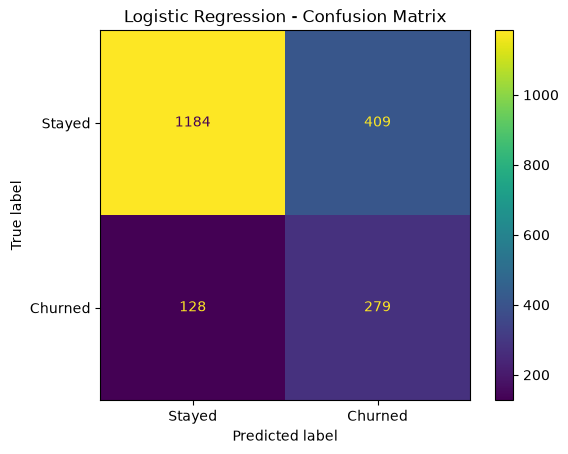

In [537]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [538]:
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": logistic_accuracy,
    "Precision": logistic_precision,
    "Recall": logistic_recall,
    "F1": logistic_f1,
    "ROC_AUC": logistic_roc_auc,
    "PR_AUC": logistic_pr_auc
}

print(logistic_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.7315, 'Precision': 0.4055232558139535, 'Recall': 0.6855036855036855, 'F1': 0.5095890410958904, 'ROC_AUC': 0.7845179540094794, 'PR_AUC': 0.5109540537972191}


In [539]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully.")

Random Forest imported successfully.


In [540]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created.")

Random Forest model created.


In [541]:
random_forest_model.fit(
    X_train_smote,
    y_train_smote
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [542]:
y_pred_rf = random_forest_model.predict(
    X_test_processed
)

print("Random Forest predictions generated.")

Random Forest predictions generated.


In [543]:
y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("First 10 churn probabilities:")
print(y_prob_rf[:10])

First 10 churn probabilities:
[0.02666667 0.08       0.06333333 0.01666667 0.08666667 0.38
 0.06333333 0.17333333 0.54       0.08333333]


In [544]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf
)

rf_recall = recall_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

rf_roc_auc = roc_auc_score(
    y_test,
    y_prob_rf
)

rf_pr_auc = average_precision_score(
    y_test,
    y_prob_rf
)

print("Random Forest")
print("-------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))
print("PR-AUC   :", round(rf_pr_auc, 4))

Random Forest
-------------
Accuracy : 0.854
Precision: 0.6638
Recall   : 0.5725
F1 Score : 0.6148
ROC-AUC  : 0.8447
PR-AUC   : 0.6469


In [545]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Stayed", "Churned"]
    )
)

              precision    recall  f1-score   support

      Stayed       0.89      0.93      0.91      1593
     Churned       0.66      0.57      0.61       407

    accuracy                           0.85      2000
   macro avg       0.78      0.75      0.76      2000
weighted avg       0.85      0.85      0.85      2000



In [546]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[1475  118]
 [ 174  233]]


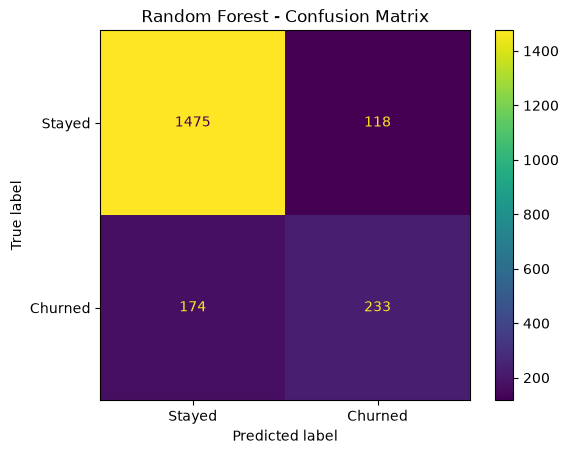

In [547]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [548]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1": rf_f1,
    "ROC_AUC": rf_roc_auc,
    "PR_AUC": rf_pr_auc
}

print(rf_results)

{'Model': 'Random Forest', 'Accuracy': 0.854, 'Precision': 0.6638176638176638, 'Recall': 0.5724815724815725, 'F1': 0.6147757255936676, 'ROC_AUC': 0.8446859802792006, 'PR_AUC': 0.646920921999141}


In [549]:
comparison_step19 = pd.DataFrame([
    logistic_results,
    rf_results
])

comparison_step19

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.7315,0.405523,0.685504,0.509589,0.784518,0.510954
1,Random Forest,0.8540,0.663818,0.572482,0.614776,0.844686,0.646921


In [550]:
!pip install xgboost

In [551]:
from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [552]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

print("XGBoost model created.")

XGBoost model created.


In [553]:
xgb_model.fit(
    X_train_smote,
    y_train_smote
)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [554]:
y_pred_xgb = xgb_model.predict(
    X_test_processed
)

print("XGBoost predictions generated.")

XGBoost predictions generated.


In [555]:
y_prob_xgb = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("First 10 XGBoost churn probabilities:")
print(y_prob_xgb[:10])

First 10 XGBoost churn probabilities:
[0.03071892 0.11641669 0.05047397 0.0469424  0.12090573 0.31596363
 0.05505779 0.25563344 0.58204556 0.08130307]


In [556]:
xgb_accuracy = accuracy_score(
    y_test,
    y_pred_xgb
)

xgb_precision = precision_score(
    y_test,
    y_pred_xgb
)

xgb_recall = recall_score(
    y_test,
    y_pred_xgb
)

xgb_f1 = f1_score(
    y_test,
    y_pred_xgb
)

xgb_roc_auc = roc_auc_score(
    y_test,
    y_prob_xgb
)

xgb_pr_auc = average_precision_score(
    y_test,
    y_prob_xgb
)

print("XGBoost")
print("-------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1 Score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_roc_auc, 4))
print("PR-AUC   :", round(xgb_pr_auc, 4))

XGBoost
-------
Accuracy : 0.857
Precision: 0.6774
Recall   : 0.5676
F1 Score : 0.6176
ROC-AUC  : 0.8629
PR-AUC   : 0.7101


In [557]:
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["Stayed", "Churned"]
    )
)

              precision    recall  f1-score   support

      Stayed       0.89      0.93      0.91      1593
     Churned       0.68      0.57      0.62       407

    accuracy                           0.86      2000
   macro avg       0.79      0.75      0.76      2000
weighted avg       0.85      0.86      0.85      2000



In [558]:
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

print("XGBoost Confusion Matrix:")
print(cm_xgb)

XGBoost Confusion Matrix:
[[1483  110]
 [ 176  231]]


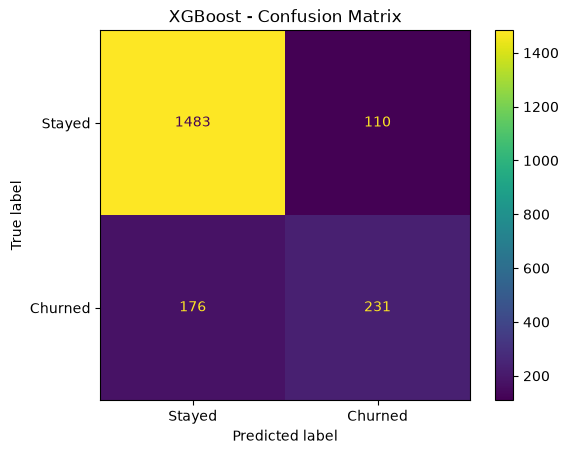

In [559]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("XGBoost - Confusion Matrix")
plt.show()

In [560]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": xgb_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "F1": xgb_f1,
    "ROC_AUC": xgb_roc_auc,
    "PR_AUC": xgb_pr_auc
}

print(xgb_results)

{'Model': 'XGBoost', 'Accuracy': 0.857, 'Precision': 0.6774193548387096, 'Recall': 0.5675675675675675, 'F1': 0.6176470588235294, 'ROC_AUC': 0.8629446087073205, 'PR_AUC': 0.7100878018648461}


In [561]:
comparison_step20 = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results
])

comparison_step20

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.7315,0.405523,0.685504,0.509589,0.784518,0.510954
1,Random Forest,0.8540,0.663818,0.572482,0.614776,0.844686,0.646921
2,XGBoost,0.8570,0.677419,0.567568,0.617647,0.862945,0.710088


In [562]:
!pip install lightgbm

In [563]:
from lightgbm import LGBMClassifier

print("LightGBM imported successfully.")

LightGBM imported successfully.


In [564]:
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("LightGBM model created.")

LightGBM model created.


In [565]:
lgbm_model.fit(
    X_train_smote,
    y_train_smote
)

print("LightGBM trained successfully.")

LightGBM trained successfully.


In [566]:
y_pred_lgbm = lgbm_model.predict(
    X_test_processed
)

print("LightGBM predictions generated.")

LightGBM predictions generated.


In [567]:
y_prob_lgbm = lgbm_model.predict_proba(
    X_test_processed
)[:, 1]

print("First 10 LightGBM churn probabilities:")
print(y_prob_lgbm[:10])

First 10 LightGBM churn probabilities:
[0.03199982 0.09890971 0.04906775 0.06010789 0.16674258 0.41293034
 0.04231576 0.25540205 0.54444434 0.08372466]


In [568]:
lgbm_accuracy = accuracy_score(
    y_test,
    y_pred_lgbm
)

lgbm_precision = precision_score(
    y_test,
    y_pred_lgbm
)

lgbm_recall = recall_score(
    y_test,
    y_pred_lgbm
)

lgbm_f1 = f1_score(
    y_test,
    y_pred_lgbm
)

lgbm_roc_auc = roc_auc_score(
    y_test,
    y_prob_lgbm
)

lgbm_pr_auc = average_precision_score(
    y_test,
    y_prob_lgbm
)

print("LightGBM")
print("--------")
print("Accuracy :", round(lgbm_accuracy, 4))
print("Precision:", round(lgbm_precision, 4))
print("Recall   :", round(lgbm_recall, 4))
print("F1 Score :", round(lgbm_f1, 4))
print("ROC-AUC  :", round(lgbm_roc_auc, 4))
print("PR-AUC   :", round(lgbm_pr_auc, 4))

LightGBM
--------
Accuracy : 0.8575
Precision: 0.6794
Recall   : 0.5676
F1 Score : 0.6185
ROC-AUC  : 0.8632
PR-AUC   : 0.709


In [569]:
print(
    classification_report(
        y_test,
        y_pred_lgbm,
        target_names=["Stayed", "Churned"]
    )
)

              precision    recall  f1-score   support

      Stayed       0.89      0.93      0.91      1593
     Churned       0.68      0.57      0.62       407

    accuracy                           0.86      2000
   macro avg       0.79      0.75      0.77      2000
weighted avg       0.85      0.86      0.85      2000



In [570]:
cm_lgbm = confusion_matrix(
    y_test,
    y_pred_lgbm
)

print("LightGBM Confusion Matrix:")
print(cm_lgbm)

LightGBM Confusion Matrix:
[[1484  109]
 [ 176  231]]


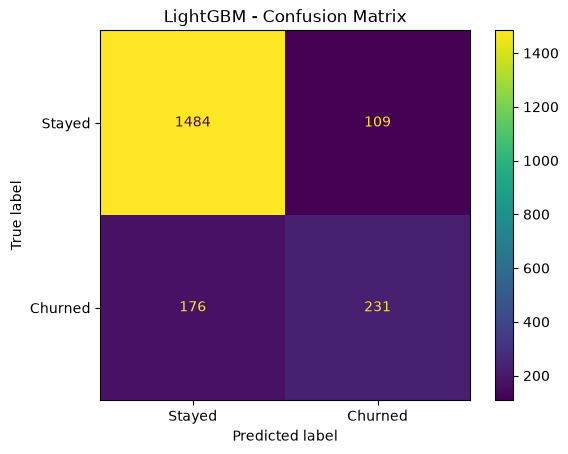

In [571]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_lgbm,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title("LightGBM - Confusion Matrix")
plt.show()

In [572]:
lgbm_results = {
    "Model": "LightGBM",
    "Accuracy": lgbm_accuracy,
    "Precision": lgbm_precision,
    "Recall": lgbm_recall,
    "F1": lgbm_f1,
    "ROC_AUC": lgbm_roc_auc,
    "PR_AUC": lgbm_pr_auc
}

print(lgbm_results)

{'Model': 'LightGBM', 'Accuracy': 0.8575, 'Precision': 0.6794117647058824, 'Recall': 0.5675675675675675, 'F1': 0.6184738955823293, 'ROC_AUC': 0.8631589987522191, 'PR_AUC': 0.7089522616540752}


In [573]:
comparison_step21 = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results,
    lgbm_results
])

comparison_step21

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.7315,0.405523,0.685504,0.509589,0.784518,0.510954
1,Random Forest,0.8540,0.663818,0.572482,0.614776,0.844686,0.646921
2,XGBoost,0.8570,0.677419,0.567568,0.617647,0.862945,0.710088
3,LightGBM,0.8575,0.679412,0.567568,0.618474,0.863159,0.708952


In [574]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline

print("Cross-validation tools imported successfully.")

Cross-validation tools imported successfully.


In [575]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation created.")


5-Fold Stratified Cross-Validation created.


In [576]:
smote_cv = SMOTE(
    random_state=42
)

print("SMOTE object created for cross-validation.")

SMOTE object created for cross-validation.


In [577]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

print("Cross-validation scoring metrics prepared.")


Cross-validation scoring metrics prepared.


In [578]:
rf_cv_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest CV pipeline created.")

Random Forest CV pipeline created.


In [579]:
rf_cv_results = cross_validate(
    rf_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest cross-validation completed.")

Random Forest cross-validation completed.


In [580]:
print("Random Forest 5-Fold Cross-Validation")
print("--------------------------------------")

for metric in scoring.keys():
    scores = rf_cv_results[f"test_{metric}"]
    
    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Random Forest 5-Fold Cross-Validation
--------------------------------------
ACCURACY  : 0.8480 ± 0.0108
PRECISION : 0.6520 ± 0.0282
RECALL    : 0.5429 ± 0.0374
F1        : 0.5924 ± 0.0335
ROC_AUC   : 0.8450 ± 0.0129
PR_AUC    : 0.6401 ± 0.0193


In [581]:
xgb_cv_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            eval_metric="logloss",
            n_jobs=-1
        ))
    ]
)

print("XGBoost CV pipeline created.")

XGBoost CV pipeline created.


In [582]:
xgb_cv_results = cross_validate(
    xgb_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("XGBoost cross-validation completed.")

XGBoost cross-validation completed.


In [583]:
print("XGBoost 5-Fold Cross-Validation")
print("--------------------------------")

for metric in scoring.keys():
    scores = xgb_cv_results[f"test_{metric}"]
    
    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

XGBoost 5-Fold Cross-Validation
--------------------------------
ACCURACY  : 0.8571 ± 0.0083
PRECISION : 0.6801 ± 0.0224
RECALL    : 0.5638 ± 0.0366
F1        : 0.6161 ± 0.0280
ROC_AUC   : 0.8607 ± 0.0103
PR_AUC    : 0.6932 ± 0.0242


In [587]:
lgbm_cv_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=5,
            num_leaves=31,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ]
)

print("LightGBM CV pipeline created.")

LightGBM CV pipeline created.


In [588]:
lgbm_cv_results = cross_validate(
    lgbm_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("LightGBM cross-validation completed.")

LightGBM cross-validation completed.


In [589]:
print("LightGBM 5-Fold Cross-Validation")
print("--------------------------------")

for metric in scoring.keys():
    scores = lgbm_cv_results[f"test_{metric}"]
    
    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

LightGBM 5-Fold Cross-Validation
--------------------------------
ACCURACY  : 0.8575 ± 0.0110
PRECISION : 0.6816 ± 0.0316
RECALL    : 0.5638 ± 0.0337
F1        : 0.6170 ± 0.0317
ROC_AUC   : 0.8606 ± 0.0124
PR_AUC    : 0.6935 ± 0.0268


In [590]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    
    "Accuracy": [
        rf_cv_results["test_accuracy"].mean(),
        xgb_cv_results["test_accuracy"].mean(),
        lgbm_cv_results["test_accuracy"].mean()
    ],
    
    "Precision": [
        rf_cv_results["test_precision"].mean(),
        xgb_cv_results["test_precision"].mean(),
        lgbm_cv_results["test_precision"].mean()
    ],
    
    "Recall": [
        rf_cv_results["test_recall"].mean(),
        xgb_cv_results["test_recall"].mean(),
        lgbm_cv_results["test_recall"].mean()
    ],
    
    "F1": [
        rf_cv_results["test_f1"].mean(),
        xgb_cv_results["test_f1"].mean(),
        lgbm_cv_results["test_f1"].mean()
    ],
    
    "ROC_AUC": [
        rf_cv_results["test_roc_auc"].mean(),
        xgb_cv_results["test_roc_auc"].mean(),
        lgbm_cv_results["test_roc_auc"].mean()
    ],
    
    "PR_AUC": [
        rf_cv_results["test_pr_auc"].mean(),
        xgb_cv_results["test_pr_auc"].mean(),
        lgbm_cv_results["test_pr_auc"].mean()
    ]
})

cv_comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.848000,0.652041,0.542945,0.592368,0.844993,0.640130
1,XGBoost,0.857125,0.680133,0.563804,0.616094,0.860651,0.693229
2,LightGBM,0.857500,0.681630,0.563804,0.616975,0.860614,0.693533


In [591]:
from sklearn.model_selection import RandomizedSearchCV

print("RandomizedSearchCV imported successfully.")

RandomizedSearchCV imported successfully.


In [592]:
tuning_scoring = "roc_auc"

print("Primary tuning metric:", tuning_scoring)

Primary tuning metric: roc_auc


In [593]:
rf_param_dist = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

print("Random Forest parameter distribution created.")

Random Forest parameter distribution created.


In [594]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_cv_pipeline,
    param_distributions=rf_param_dist,
    n_iter=15,
    scoring=tuning_scoring,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Random Forest tuning configured.")

Random Forest tuning configured.


In [595]:
rf_random_search.fit(
    X_train,
    y_train
)

print("Random Forest tuning completed.")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Random Forest tuning completed.


In [596]:
rf_random_search.fit(
    X_train,
    y_train
)

print("Random Forest tuning completed.")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Random Forest tuning completed.


In [597]:
print("Best Random Forest parameters:")
print(rf_random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(rf_random_search.best_score_, 4))

Best Random Forest parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 15}

Best CV ROC-AUC:
0.8512


In [598]:
xgb_param_dist = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

print("XGBoost parameter distribution created.")

XGBoost parameter distribution created.


In [599]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_cv_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=15,
    scoring=tuning_scoring,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("XGBoost tuning configured.")

XGBoost tuning configured.


In [600]:
xgb_random_search.fit(
    X_train,
    y_train
)

print("XGBoost tuning completed.")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
XGBoost tuning completed.


In [601]:
print("Best XGBoost parameters:")
print(xgb_random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(xgb_random_search.best_score_, 4))

Best XGBoost parameters:
{'model__subsample': 0.9, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}

Best CV ROC-AUC:
0.8623


In [602]:
lgbm_param_dist = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [-1, 3, 5, 7, 10],
    "model__num_leaves": [15, 31, 50, 70],
    "model__min_child_samples": [10, 20, 30, 50],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

print("LightGBM parameter distribution created.")

LightGBM parameter distribution created.


In [603]:
lgbm_random_search = RandomizedSearchCV(
    estimator=lgbm_cv_pipeline,
    param_distributions=lgbm_param_dist,
    n_iter=15,
    scoring=tuning_scoring,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("LightGBM tuning configured.")

LightGBM tuning configured.


In [604]:
lgbm_random_search.fit(
    X_train,
    y_train
)

print("LightGBM tuning completed.")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
LightGBM tuning completed.


In [605]:
print("Best LightGBM parameters:")
print(lgbm_random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(lgbm_random_search.best_score_, 4))

Best LightGBM parameters:
{'model__subsample': 0.8, 'model__num_leaves': 15, 'model__n_estimators': 200, 'model__min_child_samples': 30, 'model__max_depth': 10, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}

Best CV ROC-AUC:
0.8631


In [606]:
tuned_cv_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "Best_CV_ROC_AUC": [
        rf_random_search.best_score_,
        xgb_random_search.best_score_,
        lgbm_random_search.best_score_
    ]
})

tuned_cv_comparison

,Model,Best_CV_ROC_AUC
0,Random Forest,0.851208
1,XGBoost,0.862293
2,LightGBM,0.863124


In [607]:
best_rf_pipeline = rf_random_search.best_estimator_
best_xgb_pipeline = xgb_random_search.best_estimator_
best_lgbm_pipeline = lgbm_random_search.best_estimator_

print("Best tuned pipelines extracted successfully.")

Best tuned pipelines extracted successfully.


In [608]:
y_pred_rf_tuned = best_rf_pipeline.predict(X_test)
y_prob_rf_tuned = best_rf_pipeline.predict_proba(X_test)[:, 1]

print("Tuned Random Forest test predictions generated.")

Tuned Random Forest test predictions generated.


In [609]:
y_pred_xgb_tuned = best_xgb_pipeline.predict(X_test)
y_prob_xgb_tuned = best_xgb_pipeline.predict_proba(X_test)[:, 1]

print("Tuned XGBoost test predictions generated.")

Tuned XGBoost test predictions generated.


In [610]:
y_pred_lgbm_tuned = best_lgbm_pipeline.predict(X_test)
y_prob_lgbm_tuned = best_lgbm_pipeline.predict_proba(X_test)[:, 1]

print("Tuned LightGBM test predictions generated.")

Tuned LightGBM test predictions generated.


In [611]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob)
    }

print("Evaluation function created.")

Evaluation function created.


In [612]:
tuned_test_results = pd.DataFrame([
    evaluate_model(
        "Random Forest Tuned",
        y_test,
        y_pred_rf_tuned,
        y_prob_rf_tuned
    ),
    
    evaluate_model(
        "XGBoost Tuned",
        y_test,
        y_pred_xgb_tuned,
        y_prob_xgb_tuned
    ),
    
    evaluate_model(
        "LightGBM Tuned",
        y_test,
        y_pred_lgbm_tuned,
        y_prob_lgbm_tuned
    )
])

tuned_test_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest Tuned,0.8510,0.638677,0.616708,0.627500,0.852805,0.666750
1,XGBoost Tuned,0.8570,0.673352,0.577396,0.621693,0.867735,0.715515
2,LightGBM Tuned,0.8525,0.642132,0.621622,0.631710,0.869235,0.712710


In [613]:
tuned_test_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest Tuned,0.8510,0.638677,0.616708,0.627500,0.852805,0.666750
1,XGBoost Tuned,0.8570,0.673352,0.577396,0.621693,0.867735,0.715515
2,LightGBM Tuned,0.8525,0.642132,0.621622,0.631710,0.869235,0.712710


In [614]:
cv_comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.848000,0.652041,0.542945,0.592368,0.844993,0.640130
1,XGBoost,0.857125,0.680133,0.563804,0.616094,0.860651,0.693229
2,LightGBM,0.857500,0.681630,0.563804,0.616975,0.860614,0.693533


In [615]:
tuned_cv_comparison

,Model,Best_CV_ROC_AUC
0,Random Forest,0.851208
1,XGBoost,0.862293
2,LightGBM,0.863124


In [616]:
final_model_comparison = tuned_test_results.copy()

final_model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest Tuned,0.8510,0.638677,0.616708,0.627500,0.852805,0.666750
1,XGBoost Tuned,0.8570,0.673352,0.577396,0.621693,0.867735,0.715515
2,LightGBM Tuned,0.8525,0.642132,0.621622,0.631710,0.869235,0.712710


In [617]:
selection_results = tuned_test_results.copy()

selection_results["SelectionScore"] = (
    0.40 * selection_results["ROC_AUC"] +
    0.30 * selection_results["PR_AUC"] +
    0.20 * selection_results["F1"] +
    0.10 * selection_results["Recall"]
)

selection_results = selection_results.sort_values(
    "SelectionScore",
    ascending=False
).reset_index(drop=True)

selection_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,SelectionScore
0,LightGBM Tuned,0.8525,0.642132,0.621622,0.631710,0.869235,0.712710,0.750011
1,XGBoost Tuned,0.8570,0.673352,0.577396,0.621693,0.867735,0.715515,0.743827
2,Random Forest Tuned,0.8510,0.638677,0.616708,0.627500,0.852805,0.666750,0.728318


In [618]:
final_model_name = selection_results.loc[0, "Model"]

print("Final selected model:", final_model_name)

Final selected model: LightGBM Tuned


In [619]:
if final_model_name == "Random Forest Tuned":
    final_model_pipeline = best_rf_pipeline

elif final_model_name == "XGBoost Tuned":
    final_model_pipeline = best_xgb_pipeline

elif final_model_name == "LightGBM Tuned":
    final_model_pipeline = best_lgbm_pipeline

else:
    raise ValueError("Unexpected model name.")

print("Final model pipeline selected successfully.")

Final model pipeline selected successfully.


In [620]:
final_model_pipeline

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](15,)","['CreditScore','Geography','Gender',...,'TenureBucket','InactiveFlag', 'AgeGroup']"
n_features_in_,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [621]:
final_y_pred = final_model_pipeline.predict(X_test)

final_y_prob = final_model_pipeline.predict_proba(
    X_test
)[:, 1]

print("Final model test predictions generated.")

Final model test predictions generated.


In [622]:
final_metrics = evaluate_model(
    final_model_name,
    y_test,
    final_y_pred,
    final_y_prob
)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")

for metric, value in final_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

FINAL MODEL PERFORMANCE
-----------------------
Accuracy: 0.8525
Precision: 0.6421
Recall: 0.6216
F1: 0.6317
ROC_AUC: 0.8692
PR_AUC: 0.7127


In [623]:
final_cm = confusion_matrix(
    y_test,
    final_y_pred
)

print("Final Confusion Matrix:")
print(final_cm)

Final Confusion Matrix:
[[1452  141]
 [ 154  253]]


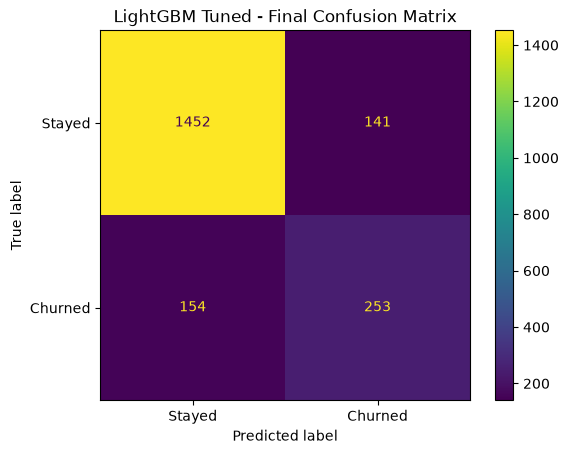

In [624]:
ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Stayed", "Churned"]
).plot()

plt.title(f"{final_model_name} - Final Confusion Matrix")
plt.show()

In [625]:
final_model_summary = pd.DataFrame([final_metrics])

final_model_summary

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LightGBM Tuned,0.8525,0.642132,0.621622,0.63171,0.869235,0.71271


In [626]:
baseline_vs_final = pd.DataFrame([
    logistic_results,
    final_metrics
])

baseline_vs_final

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.7315,0.405523,0.685504,0.509589,0.784518,0.510954
1,LightGBM Tuned,0.8525,0.642132,0.621622,0.631710,0.869235,0.712710


In [627]:
selection_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,SelectionScore
0,LightGBM Tuned,0.8525,0.642132,0.621622,0.631710,0.869235,0.712710,0.750011
1,XGBoost Tuned,0.8570,0.673352,0.577396,0.621693,0.867735,0.715515,0.743827
2,Random Forest Tuned,0.8510,0.638677,0.616708,0.627500,0.852805,0.666750,0.728318


In [628]:
# Create a sample customer for prediction

sample_customer = pd.DataFrame({
    "CreditScore": [600],
    "Geography": ["France"],
    "Gender": ["Male"],
    "Age": [40],
    "Tenure": [3],
    "Balance": [60000],
    "NumOfProducts": [2],
    "HasCrCard": [1],
    "IsActiveMember": [0],
    "EstimatedSalary": [50000],
    "BalanceSalaryRatio": [60000 / (50000 + 1)],
    "ProductEngagementScore": [2 * (1 + 0)],
    "TenureBucket": ["3-5"],
    "InactiveFlag": [1],
    "AgeGroup": ["36-45"]
})

sample_customer

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,ProductEngagementScore,TenureBucket,InactiveFlag,AgeGroup
0,600,France,Male,40,3,60000,2,1,0,50000,1.199976,2,3-5,1,36-45


In [629]:
# Predict churn probability

customer_churn_probability = final_model_pipeline.predict_proba(
    sample_customer
)[:, 1][0]

print(f"Churn Probability: {customer_churn_probability:.2%}")

Churn Probability: 15.91%


In [630]:
# Predict churn class

customer_prediction = final_model_pipeline.predict(
    sample_customer
)[0]

if customer_prediction == 1:
    churn_status = "Churned"
else:
    churn_status = "Stayed"

print("Predicted Status:", churn_status)

Predicted Status: Stayed


In [631]:
# Define churn risk category

if customer_churn_probability >= 0.70:
    risk_category = "High Risk"

elif customer_churn_probability >= 0.40:
    risk_category = "Medium Risk"

else:
    risk_category = "Low Risk"

print("Risk Category:", risk_category)

Risk Category: Low Risk


In [632]:
# Create customer-level prediction result

customer_prediction_result = sample_customer.copy()

customer_prediction_result["Churn_Probability"] = customer_churn_probability
customer_prediction_result["Predicted_Status"] = churn_status
customer_prediction_result["Risk_Category"] = risk_category

customer_prediction_result

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,ProductEngagementScore,TenureBucket,InactiveFlag,AgeGroup,Churn_Probability,Predicted_Status,Risk_Category
0,600,France,Male,40,3,60000,2,1,0,50000,1.199976,2,3-5,1,36-45,0.159113,Stayed,Low Risk


In [633]:
print("CUSTOMER CHURN PREDICTION")
print("-------------------------")
print(f"Churn Probability : {customer_churn_probability:.2%}")
print(f"Predicted Status  : {churn_status}")
print(f"Risk Category     : {risk_category}")

CUSTOMER CHURN PREDICTION
-------------------------
Churn Probability : 15.91%
Predicted Status  : Stayed
Risk Category     : Low Risk


In [634]:
def calculate_estimated_ltv(customer):
    
    balance_value = 0.02 * customer["Balance"]
    salary_value = 0.005 * customer["EstimatedSalary"]
    product_value = 500 * customer["NumOfProducts"]
    activity_value = 500 * customer["IsActiveMember"]
    
    annual_value = (
        balance_value
        + salary_value
        + product_value
        + activity_value
    )
    
    remaining_tenure = max(0, 10 - customer["Tenure"])
    
    estimated_ltv = annual_value * remaining_tenure
    
    return estimated_ltv

In [635]:
sample_ltv = calculate_estimated_ltv(sample_customer.iloc[0])

print(f"Estimated Customer LTV: ₹{sample_ltv:,.2f}")

Estimated Customer LTV: ₹17,150.00


In [636]:
customer_prediction_result["Estimated_LTV"] = sample_ltv

customer_prediction_result[
    [
        "Churn_Probability",
        "Predicted_Status",
        "Risk_Category",
        "Estimated_LTV"
    ]
]

,Churn_Probability,Predicted_Status,Risk_Category,Estimated_LTV
0,0.159113,Stayed,Low Risk,17150.0


In [637]:
expected_churn_value = (
    customer_churn_probability * sample_ltv
)

print(f"Expected Value at Risk: ₹{expected_churn_value:,.2f}")

Expected Value at Risk: ₹2,728.78


In [638]:
customer_prediction_result["Expected_Value_At_Risk"] = expected_churn_value

customer_prediction_result[
    [
        "Churn_Probability",
        "Risk_Category",
        "Estimated_LTV",
        "Expected_Value_At_Risk"
    ]
]

,Churn_Probability,Risk_Category,Estimated_LTV,Expected_Value_At_Risk
0,0.159113,Low Risk,17150.0,2728.780472


In [639]:
def calculate_retention_cost(risk_category):
    
    if risk_category == "High Risk":
        return 2000
    
    elif risk_category == "Medium Risk":
        return 1000
    
    else:
        return 300

In [640]:
retention_cost = calculate_retention_cost(
    risk_category
)

print(f"Estimated Retention Cost: ₹{retention_cost:,.2f}")

Estimated Retention Cost: ₹300.00


In [641]:
def calculate_retention_success_probability(risk_category):
    
    if risk_category == "High Risk":
        return 0.40
    
    elif risk_category == "Medium Risk":
        return 0.60
    
    else:
        return 0.80

In [642]:
retention_success_probability = (
    calculate_retention_success_probability(
        risk_category
    )
)

expected_retention_value = (
    customer_churn_probability
    * sample_ltv
    * retention_success_probability
)

print(
    f"Expected Retention Value: "
    f"₹{expected_retention_value:,.2f}"
)

Expected Retention Value: ₹2,183.02


In [643]:
expected_net_retention_value = (
    expected_retention_value
    - retention_cost
)

print(
    f"Expected Net Retention Value: "
    f"₹{expected_net_retention_value:,.2f}"
)

Expected Net Retention Value: ₹1,883.02


In [644]:
customer_prediction_result["Retention_Cost"] = retention_cost

customer_prediction_result[
    "Retention_Success_Probability"
] = retention_success_probability

customer_prediction_result[
    "Expected_Retention_Value"
] = expected_retention_value

customer_prediction_result[
    "Expected_Net_Retention_Value"
] = expected_net_retention_value

In [645]:
customer_prediction_result[
    [
        "Churn_Probability",
        "Risk_Category",
        "Estimated_LTV",
        "Expected_Value_At_Risk",
        "Retention_Cost",
        "Retention_Success_Probability",
        "Expected_Retention_Value",
        "Expected_Net_Retention_Value"
    ]
]

,Churn_Probability,Risk_Category,Estimated_LTV,Expected_Value_At_Risk,Retention_Cost,Retention_Success_Probability,Expected_Retention_Value,Expected_Net_Retention_Value
0,0.159113,Low Risk,17150.0,2728.780472,300,0.8,2183.024378,1883.024378


In [646]:
retention_priority_score = expected_net_retention_value

print(
    f"Retention Priority Score: "
    f"₹{retention_priority_score:,.2f}"
)

Retention Priority Score: ₹1,883.02


In [647]:
retention_priority_score = expected_net_retention_value

print(
    f"Retention Priority Score: "
    f"₹{retention_priority_score:,.2f}"
)

Retention Priority Score: ₹1,883.02


In [648]:
def determine_retention_priority(
    risk_category,
    expected_net_value
):
    
    if expected_net_value <= 0:
        return "Low Priority"
    
    elif risk_category == "High Risk":
        return "Priority Retention"
    
    elif risk_category == "Medium Risk":
        return "Targeted Retention"
    
    else:
        return "Monitor"

In [649]:
retention_priority = determine_retention_priority(
    risk_category,
    expected_net_retention_value
)

print("Retention Priority:", retention_priority)

Retention Priority: Monitor


In [650]:
def generate_retention_recommendation(
    risk_category,
    retention_priority
):
    
    if retention_priority == "Priority Retention":
        return (
            "Initiate personalized retention intervention "
            "and relationship-manager follow-up."
        )
    
    elif retention_priority == "Targeted Retention":
        return (
            "Provide a targeted retention offer or "
            "personalized communication."
        )
    
    elif retention_priority == "Monitor":
        return (
            "Monitor customer activity and maintain "
            "regular engagement."
        )
    
    else:
        return (
            "Avoid costly intervention; use low-cost "
            "automated communication if necessary."
        )

In [651]:
retention_recommendation = generate_retention_recommendation(
    risk_category,
    retention_priority
)

print("Recommended Action:")
print(retention_recommendation)

Recommended Action:
Monitor customer activity and maintain regular engagement.


In [652]:
customer_prediction_result[
    "Retention_Priority"
] = retention_priority

customer_prediction_result[
    "Recommended_Action"
] = retention_recommendation

In [653]:
customer_prediction_result[
    [
        "Churn_Probability",
        "Risk_Category",
        "Estimated_LTV",
        "Expected_Value_At_Risk",
        "Retention_Cost",
        "Retention_Success_Probability",
        "Expected_Retention_Value",
        "Expected_Net_Retention_Value",
        "Retention_Priority",
        "Recommended_Action"
    ]
]

,Churn_Probability,Risk_Category,Estimated_LTV,Expected_Value_At_Risk,Retention_Cost,Retention_Success_Probability,Expected_Retention_Value,Expected_Net_Retention_Value,Retention_Priority,Recommended_Action
0,0.159113,Low Risk,17150.0,2728.780472,300,0.8,2183.024378,1883.024378,Monitor,Monitor customer activity and maintain regular...


In [654]:
print("==============================================")
print("     COST-SENSITIVE RETENTION ANALYSIS")
print("==============================================")

print(f"Churn Probability       : {customer_churn_probability:.2%}")
print(f"Risk Category           : {risk_category}")
print(f"Estimated LTV           : ₹{sample_ltv:,.2f}")
print(f"Expected Value at Risk  : ₹{expected_churn_value:,.2f}")
print(f"Retention Cost          : ₹{retention_cost:,.2f}")
print(
    f"Retention Success       : "
    f"{retention_success_probability:.2%}"
)
print(
    f"Expected Retention Value: "
    f"₹{expected_retention_value:,.2f}"
)
print(
    f"Expected Net Value      : "
    f"₹{expected_net_retention_value:,.2f}"
)
print(f"Retention Priority      : {retention_priority}")

print("----------------------------------------------")
print("Recommended Action:")
print(retention_recommendation)
print("==============================================")

     COST-SENSITIVE RETENTION ANALYSIS
Churn Probability       : 15.91%
Risk Category           : Low Risk
Estimated LTV           : ₹17,150.00
Expected Value at Risk  : ₹2,728.78
Retention Cost          : ₹300.00
Retention Success       : 80.00%
Expected Retention Value: ₹2,183.02
Expected Net Value      : ₹1,883.02
Retention Priority      : Monitor
----------------------------------------------
Recommended Action:
Monitor customer activity and maintain regular engagement.


In [655]:
# Create evaluation dataframe from the test set

evaluation_df = X_test.copy()

evaluation_df["Actual_Churn"] = y_test.values
evaluation_df["Churn_Probability"] = final_y_prob

evaluation_df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,ProductEngagementScore,TenureBucket,InactiveFlag,AgeGroup,Actual_Churn,Churn_Probability
5702,585,France,Male,36,7,0.00,2,1,0,94283.09,0.000000,2,6-8,1,36-45,0,0.049671
3667,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,2.379052,2,3-5,1,26-35,0,0.127871
1617,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0.000000,4,3-5,0,36-45,0,0.084541
5673,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,4.105707,2,3-5,1,26-35,0,0.090508
4272,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0.461754,2,3-5,0,26-35,0,0.195310


In [656]:
# Calculate estimated LTV for every test customer

evaluation_df["Estimated_LTV"] = evaluation_df.apply(
    calculate_estimated_ltv,
    axis=1
)

evaluation_df[
    [
        "Churn_Probability",
        "Estimated_LTV",
        "Actual_Churn"
    ]
].head()

,Churn_Probability,Estimated_LTV,Actual_Churn
5702,0.049671,4414.24635,0
3667,0.127871,23375.03910,0
1617,0.084541,12163.00590,0
5673,0.090508,19788.07100,0
4272,0.195310,23794.82175,0


In [657]:
evaluation_df["Expected_Value_At_Risk"] = (
    evaluation_df["Churn_Probability"]
    * evaluation_df["Estimated_LTV"]
)

evaluation_df[
    [
        "Churn_Probability",
        "Estimated_LTV",
        "Expected_Value_At_Risk"
    ]
].head()

,Churn_Probability,Estimated_LTV,Expected_Value_At_Risk
5702,0.049671,4414.24635,219.259398
3667,0.127871,23375.03910,2988.992982
1617,0.084541,12163.00590,1028.274161
5673,0.090508,19788.07100,1790.987250
4272,0.195310,23794.82175,4647.364774


In [658]:
# Assign risk category to every test customer

evaluation_df["Risk_Category"] = evaluation_df[
    "Churn_Probability"
].apply(
    lambda x:
        "High Risk" if x >= 0.70
        else "Medium Risk" if x >= 0.40
        else "Low Risk"
)

evaluation_df["Retention_Cost"] = evaluation_df[
    "Risk_Category"
].apply(
    calculate_retention_cost
)

evaluation_df[
    [
        "Churn_Probability",
        "Risk_Category",
        "Retention_Cost"
    ]
].head()

,Churn_Probability,Risk_Category,Retention_Cost
5702,0.049671,Low Risk,300
3667,0.127871,Low Risk,300
1617,0.084541,Low Risk,300
5673,0.090508,Low Risk,300
4272,0.195310,Low Risk,300


In [659]:
evaluation_df["Retention_Success_Probability"] = (
    evaluation_df["Risk_Category"].apply(
        calculate_retention_success_probability
    )
)

evaluation_df["Expected_Retention_Value"] = (
    evaluation_df["Churn_Probability"]
    * evaluation_df["Estimated_LTV"]
    * evaluation_df["Retention_Success_Probability"]
)

evaluation_df["Expected_Net_Retention_Value"] = (
    evaluation_df["Expected_Retention_Value"]
    - evaluation_df["Retention_Cost"]
)

evaluation_df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,...,AgeGroup,Actual_Churn,Churn_Probability,Estimated_LTV,Expected_Value_At_Risk,Risk_Category,Retention_Cost,Retention_Success_Probability,Expected_Retention_Value,Expected_Net_Retention_Value
5702,585,France,Male,36,7,0.00,2,1,0,94283.09,...,36-45,0,0.049671,4414.24635,219.259398,Low Risk,300,0.8,175.407519,-124.592481
3667,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,...,26-35,0,0.127871,23375.03910,2988.992982,Low Risk,300,0.8,2391.194385,2091.194385
1617,557,Spain,Female,40,4,0.00,2,0,1,105433.53,...,36-45,0,0.084541,12163.00590,1028.274161,Low Risk,300,0.8,822.619329,522.619329
5673,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,...,26-35,0,0.090508,19788.07100,1790.987250,Low Risk,300,0.8,1432.789800,1132.789800
4272,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,...,26-35,0,0.195310,23794.82175,4647.364774,Low Risk,300,0.8,3717.891819,3417.891819


In [660]:
import numpy as np

np.random.seed(42)

evaluation_df["Random_Score"] = np.random.random(
    len(evaluation_df)
)

In [661]:
import numpy as np

np.random.seed(42)

evaluation_df["Random_Score"] = np.random.random(
    len(evaluation_df)
)

In [662]:
evaluation_df["Churn_Strategy_Score"] = (
    evaluation_df["Churn_Probability"]
)

In [663]:
evaluation_df["Churn_LTV_Score"] = (
    evaluation_df["Churn_Probability"]
    * evaluation_df["Estimated_LTV"]
)

In [664]:
evaluation_df["Cost_Sensitive_Score"] = (
    evaluation_df["Expected_Net_Retention_Value"]
)

In [665]:
RETENTION_BUDGET = 500000

print(
    f"Retention Budget: ₹{RETENTION_BUDGET:,.2f}"
)

Retention Budget: ₹500,000.00


In [666]:
def select_customers_within_budget(
    df,
    score_column,
    budget
):
    
    sorted_df = df.sort_values(
        score_column,
        ascending=False
    ).copy()
    
    selected_customers = []
    total_cost = 0
    
    for index, row in sorted_df.iterrows():
        
        cost = row["Retention_Cost"]
        
        if total_cost + cost <= budget:
            selected_customers.append(index)
            total_cost += cost
    
    return sorted_df.loc[selected_customers], total_cost

In [667]:
random_selected, random_cost = (
    select_customers_within_budget(
        evaluation_df,
        "Random_Score",
        RETENTION_BUDGET
    )
)

churn_selected, churn_cost = (
    select_customers_within_budget(
        evaluation_df,
        "Churn_Strategy_Score",
        RETENTION_BUDGET
    )
)

churn_ltv_selected, churn_ltv_cost = (
    select_customers_within_budget(
        evaluation_df,
        "Churn_LTV_Score",
        RETENTION_BUDGET
    )
)

cost_sensitive_selected, cost_sensitive_cost = (
    select_customers_within_budget(
        evaluation_df,
        "Cost_Sensitive_Score",
        RETENTION_BUDGET
    )
)

In [668]:
def calculate_business_metrics(selected_df):
    
    customers_targeted = len(selected_df)
    
    actual_churners_targeted = selected_df[
        "Actual_Churn"
    ].sum()
    
    expected_value = selected_df[
        "Expected_Retention_Value"
    ].sum()
    
    retention_cost = selected_df[
        "Retention_Cost"
    ].sum()
    
    net_value = expected_value - retention_cost
    
    return {
        "Customers_Targeted": customers_targeted,
        "Actual_Churners_Targeted": actual_churners_targeted,
        "Expected_Retention_Value": expected_value,
        "Retention_Cost": retention_cost,
        "Net_Value": net_value
    }

In [669]:
business_comparison = pd.DataFrame([
    {
        "Strategy": "Random Targeting",
        **calculate_business_metrics(random_selected)
    },
    {
        "Strategy": "Highest Churn Probability",
        **calculate_business_metrics(churn_selected)
    },
    {
        "Strategy": "Churn Probability × LTV",
        **calculate_business_metrics(churn_ltv_selected)
    },
    {
        "Strategy": "Cost-Sensitive Retention",
        **calculate_business_metrics(cost_sensitive_selected)
    }
])

business_comparison

,Strategy,Customers_Targeted,Actual_Churners_Targeted,Expected_Retention_Value,Retention_Cost,Net_Value
0,Random Targeting,872,168,2.492546e+06,499800,1.992746e+06
1,Highest Churn Probability,284,210,1.733387e+06,500000,1.233387e+06
2,Churn Probability × LTV,426,211,3.385259e+06,499900,2.885359e+06
3,Cost-Sensitive Retention,609,213,4.097350e+06,500000,3.597350e+06


In [670]:
!pip install shap

In [671]:
import shap
import matplotlib.pyplot as plt

In [672]:
print("Final Selected Model:")
print(final_model_name)

Final Selected Model:
LightGBM Tuned


In [673]:
final_preprocessor = final_model_pipeline.named_steps[
    "preprocessor"
]

X_test_transformed = final_preprocessor.transform(
    X_test
)

print("Transformed test shape:", X_test_transformed.shape)

Transformed test shape: (2000, 25)


In [674]:
final_feature_names = (
    final_preprocessor.get_feature_names_out()
)

print("Number of features:", len(final_feature_names))
print(final_feature_names)

Number of features: 25
['num__CreditScore' 'num__Age' 'num__Tenure' 'num__Balance'
 'num__NumOfProducts' 'num__HasCrCard' 'num__IsActiveMember'
 'num__EstimatedSalary' 'num__BalanceSalaryRatio'
 'num__ProductEngagementScore' 'num__InactiveFlag' 'cat__Geography_France'
 'cat__Geography_Germany' 'cat__Geography_Spain' 'cat__Gender_Female'
 'cat__Gender_Male' 'cat__TenureBucket_0-2' 'cat__TenureBucket_3-5'
 'cat__TenureBucket_6-8' 'cat__TenureBucket_9-10' 'cat__AgeGroup_18-25'
 'cat__AgeGroup_26-35' 'cat__AgeGroup_36-45' 'cat__AgeGroup_46-55'
 'cat__AgeGroup_56+']


In [680]:
final_trained_model = final_model_pipeline.named_steps["model"]

print("Final trained model extracted successfully.")
print(final_trained_model)

Final trained model extracted successfully.
LGBMClassifier(colsample_bytree=0.7, learning_rate=0.03, max_depth=10,
               min_child_samples=30, n_estimators=200, n_jobs=-1, num_leaves=15,
               random_state=42, subsample=0.8, verbosity=-1)


In [681]:
explainer = shap.TreeExplainer(
    final_trained_model
)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [682]:
shap_values = explainer.shap_values(
    X_test_transformed
)

print("SHAP values calculated.")

SHAP values calculated.


In [683]:
if isinstance(shap_values, list):
    shap_values_churn = shap_values[1]
else:
    shap_values_churn = shap_values

print(
    "SHAP value shape:",
    shap_values_churn.shape
)

SHAP value shape: (2000, 25)


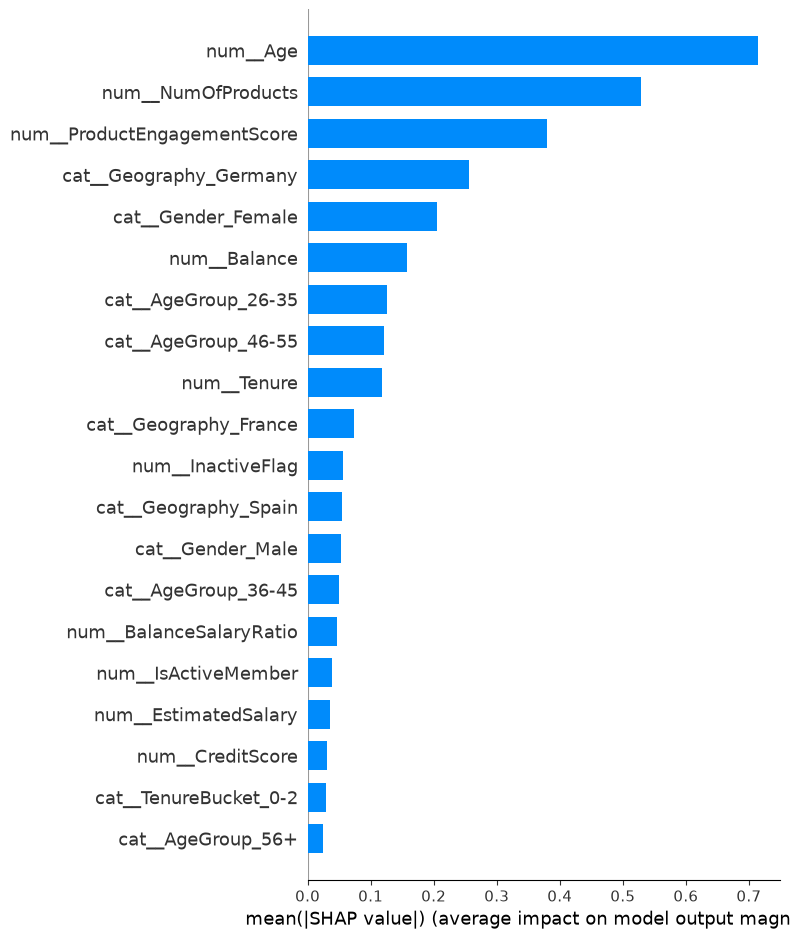

In [684]:
shap.summary_plot(
    shap_values_churn,
    X_test_transformed,
    feature_names=final_feature_names,
    plot_type="bar"
)

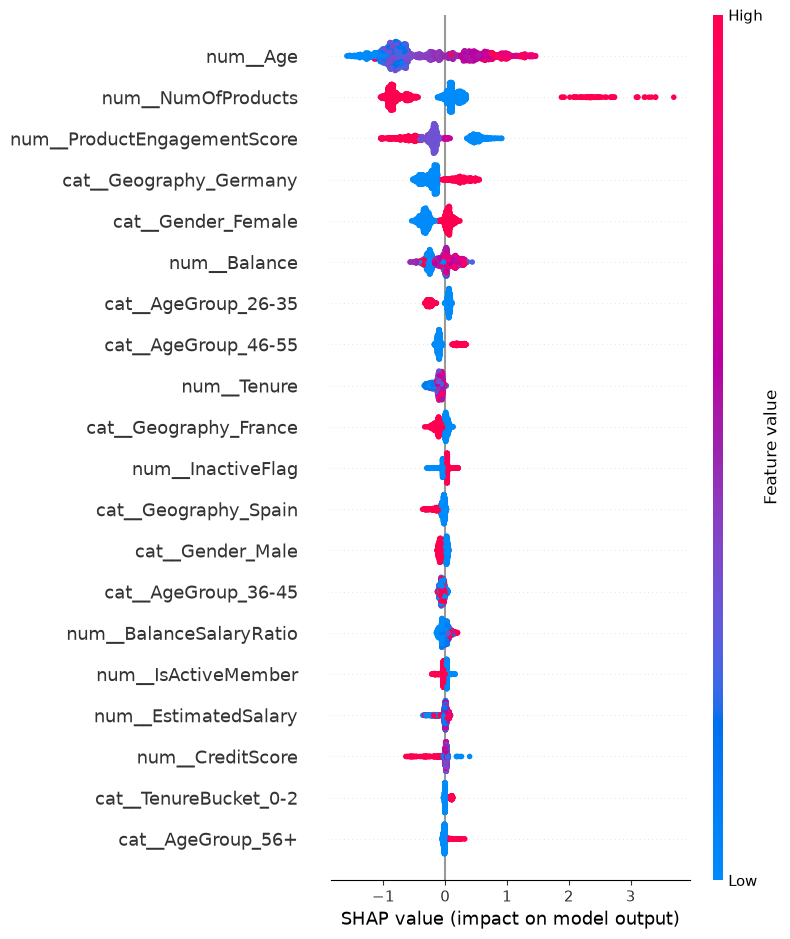

In [685]:
shap.summary_plot(
    shap_values_churn,
    X_test_transformed,
    feature_names=final_feature_names
)

In [686]:
sample_customer_transformed = final_preprocessor.transform(
    sample_customer
)

print(
    "Sample customer transformed shape:",
    sample_customer_transformed.shape
)

Sample customer transformed shape: (1, 25)


In [687]:
sample_shap_values = explainer.shap_values(
    sample_customer_transformed
)

if isinstance(sample_shap_values, list):
    sample_shap_churn = sample_shap_values[1][0]
else:
    sample_shap_churn = sample_shap_values[0]

print("Individual SHAP values calculated.")

Individual SHAP values calculated.


In [688]:
sample_feature_impact = pd.DataFrame({
    "Feature": final_feature_names,
    "SHAP_Value": sample_shap_churn
})

sample_feature_impact["Absolute_Impact"] = (
    sample_feature_impact["SHAP_Value"].abs()
)

sample_feature_impact = (
    sample_feature_impact
    .sort_values(
        "Absolute_Impact",
        ascending=False
    )
    .reset_index(drop=True)
)

sample_feature_impact.head(10)

,Feature,SHAP_Value,Absolute_Impact
0,num__NumOfProducts,-0.632352,0.632352
1,cat__Gender_Female,-0.358200,0.358200
2,num__Age,-0.242619,0.242619
3,num__ProductEngagementScore,-0.238488,0.238488
4,cat__Geography_Germany,-0.182578,0.182578
5,num__Balance,0.165517,0.165517
6,cat__AgeGroup_46-55,-0.115522,0.115522
7,cat__Gender_Male,-0.105196,0.105196
8,num__Tenure,-0.099427,0.099427
9,cat__AgeGroup_26-35,0.074200,0.074200


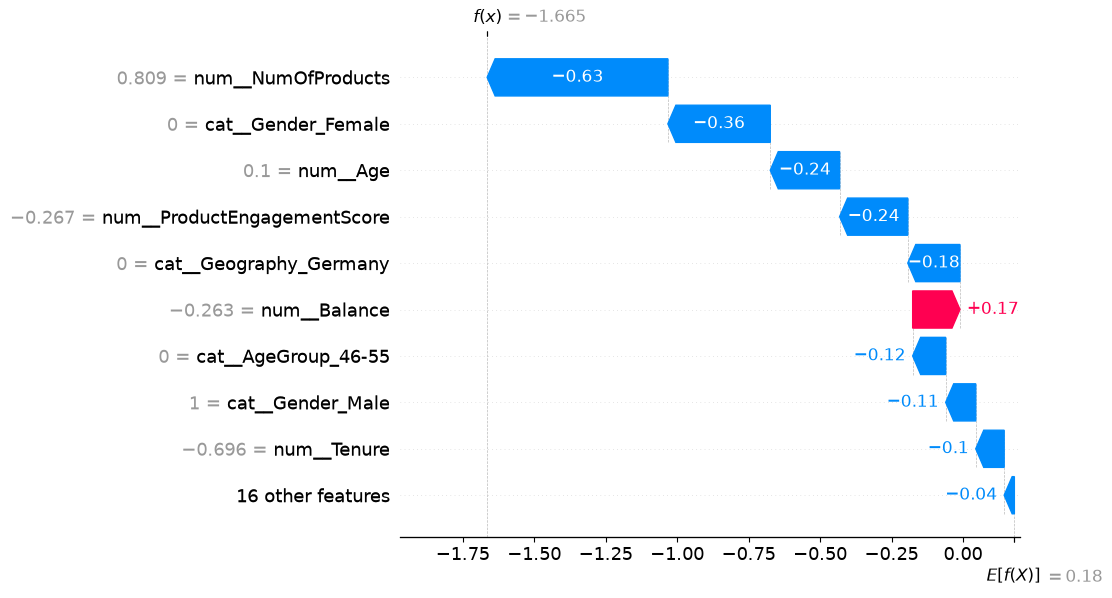

In [689]:
shap_explanation = shap.Explanation(
    values=sample_shap_churn,
    base_values=explainer.expected_value[1]
        if isinstance(explainer.expected_value, (list, np.ndarray))
        else explainer.expected_value,
    data=sample_customer_transformed[0],
    feature_names=final_feature_names
)

shap.plots.waterfall(
    shap_explanation,
    max_display=10
)

In [690]:
import joblib
import os

In [691]:
os.makedirs("saved_model", exist_ok=True)

print("saved_model folder created.")

saved_model folder created.


In [692]:
joblib.dump(
    final_model_pipeline,
    "saved_model/final_model_pipeline.pkl"
)

print("Final model pipeline saved successfully.")

Final model pipeline saved successfully.


In [693]:
joblib.dump(
    final_model_name,
    "saved_model/final_model_name.pkl"
)

print("Final model name saved successfully.")

Final model name saved successfully.


In [694]:
model_information = {
    "feature_names": X.columns.tolist(),
    "processed_feature_names": final_feature_names.tolist()
}

joblib.dump(
    model_information,
    "saved_model/model_information.pkl"
)

print("Model information saved successfully.")

Model information saved successfully.


In [695]:
business_assumptions = {
    "balance_value_rate": 0.02,
    "salary_value_rate": 0.005,
    "product_value": 500,
    "activity_value": 500,
    "high_risk_retention_cost": 2000,
    "medium_risk_retention_cost": 1000,
    "low_risk_retention_cost": 300,
    "high_risk_success_probability": 0.40,
    "medium_risk_success_probability": 0.60,
    "low_risk_success_probability": 0.80
}

joblib.dump(
    business_assumptions,
    "saved_model/business_assumptions.pkl"
)

print("Business assumptions saved successfully.")

Business assumptions saved successfully.


In [696]:
print("Saved model files:")

for file in os.listdir("saved_model"):
    print("-", file)

Saved model files:
- business_assumptions.pkl
- final_model_name.pkl
- final_model_pipeline.pkl
- model_information.pkl


In [697]:
loaded_model_pipeline = joblib.load(
    "saved_model/final_model_pipeline.pkl"
)

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [698]:
loaded_probability = loaded_model_pipeline.predict_proba(
    sample_customer
)[:, 1][0]

print(
    f"Loaded Model Churn Probability: "
    f"{loaded_probability:.2%}"
)

Loaded Model Churn Probability: 15.91%


In [699]:
print(
    "Original probability:",
    f"{customer_churn_probability:.10f}"
)

print(
    "Loaded probability  :",
    f"{loaded_probability:.10f}"
)

print(
    "Match:",
    np.isclose(
        customer_churn_probability,
        loaded_probability
    )
)

Original probability: 0.1591125640
Loaded probability  : 0.1591125640
Match: True


In [701]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [703]:
import os

print(os.getcwd())

C:\Users\hrish


In [704]:
import os

project_folder = os.path.join(
    os.path.expanduser("~"),
    "Downloads",
    "Bank_Customer_Churn_Project"
)

os.makedirs(project_folder, exist_ok=True)

print("Project folder created:")
print(project_folder)

Project folder created:
C:\Users\hrish\Downloads\Bank_Customer_Churn_Project


In [705]:
saved_model_folder = os.path.join(
    project_folder,
    "saved_model"
)

os.makedirs(saved_model_folder, exist_ok=True)

print("Saved model folder created:")
print(saved_model_folder)

Saved model folder created:
C:\Users\hrish\Downloads\Bank_Customer_Churn_Project\saved_model


In [706]:
import os

print(os.listdir("saved_model"))

['business_assumptions.pkl', 'final_model_name.pkl', 'final_model_pipeline.pkl', 'model_information.pkl']


In [707]:
import shutil
import os

source_folder = os.path.abspath("saved_model")

for file_name in os.listdir(source_folder):
    source = os.path.join(source_folder, file_name)
    destination = os.path.join(saved_model_folder, file_name)
    
    shutil.copy2(source, destination)

print("Model files copied successfully.")

Model files copied successfully.


In [708]:
for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level
    
    print(f"{indent}{os.path.basename(root)}/")
    
    for file in files:
        print(f"{indent}    {file}")

Bank_Customer_Churn_Project/
    saved_model/
        business_assumptions.pkl
        final_model_name.pkl
        final_model_pipeline.pkl
        model_information.pkl
